# 05 – Dự đoán loại hình phù hợp với vị trí (Model & Evaluation)

**Câu hỏi:** chỉ dựa vào *môi trường xung quanh* một vị trí (các quán lân cận, mật độ, khoảng cách tới sông/hotspot, phường), có đoán được ở đó là loại hình F&B nào không?
Nếu đoán được tốt hơn ngẫu nhiên, xác suất của mô hình chính là **mức độ phù hợp** của từng loại hình với vị trí đó (dùng ở notebook 06).

- **Nhãn:** `type_group`, gồm 9 nhóm. Bỏ nhóm "Khác" (78 cửa hàng chỉ có nhãn chung chung) khỏi tập huấn luyện, nhưng vẫn tính nhóm này khi đếm môi trường xung quanh.
- **Chống rò rỉ nhãn:**
  - Không dùng tên, nhãn productType, `n_types`, chain hay rating của *chính* cửa hàng, vì khi gợi ý cho vị trí mới thì chưa có những thông tin này.
  - Mọi phép đếm lân cận đều **loại chính điểm đó** (BallTree haversine).
- **Chống rò rỉ không gian:** so sánh StratifiedKFold ngẫu nhiên với **GroupKFold theo ô lưới 500 m**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from src import cleaning as cl, geo, features as ft, viz

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
viz.set_style()
PROC = ROOT / "data" / "processed"
TABLES = viz.TABLE_DIR

import joblib
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import SMOTE
from src import modeling as md

df = pd.read_csv(PROC / "stores_clean.csv")
df["type_group"] = [ft.primary_group(t, c) for t, c in zip(df["product_types"], df["category"])]
df = df.merge(pd.read_csv(PROC / "stores_clusters.csv"), on="storeId", how="left")
prof = pd.read_csv(TABLES / "cluster_profiles.csv")
print(df.shape)

(3208, 53)


## 1. Feature engineering không gian

| Nhóm đặc trưng | Cột | Ý nghĩa |
|---|---|---|
| Mật độ | `n_total_{50,100,300,500}m` | tổng số cửa hàng trong bán kính (không tính chính nó) |
| Cơ cấu gần (50 m) | `n_<nhóm>_50m`, `share_<nhóm>_50m` | số lượng / tỉ lệ từng nhóm loại hình ở sát bên (cùng dãy phố) |
| Cơ cấu khu vực (300 m) | `n_<nhóm>_300m`, `share_<nhóm>_300m`, `n_types_unique_300m` | cơ cấu thị trường trong khoảng 3–4 phút đi bộ |
| Chất lượng khu vực | `chain_share_300m`, `mean_rating_300m` | tỉ lệ chuỗi và rating TB của các quán **xung quanh** |
| Khoảng cách | `dist_nearest_m`, `dist_river_m`, `dist_hotspot_m` | tới quán gần nhất, tới sông Hàn (xấp xỉ lon 108,224), tới tâm hotspot DBSCAN gần nhất |
| Hotspot / phường | `is_hotspot`, `ward_*` | thuộc hotspot DBSCAN (notebook 03); phường (one-hot) |

**Vì sao không có số đối thủ cùng loại trong 300 m?** Đề gợi ý đặc trưng này cho bài toán dự đoán rating. Trong bài toán dự đoán **loại hình**, "cùng loại" phụ thuộc chính nhãn cần đoán, nên dùng nó là rò rỉ nhãn.
Thông tin tương đương đã nằm trong các cột `n_<nhóm>_300m` (số quán *mỗi* nhóm). Số đối thủ cùng loại vẫn được dùng ở notebook 06 để chấm điểm vị trí, khi loại hình đã được chọn trước.

**Vì sao không dùng tọa độ thô (lat/lon)?** Thử nghiệm cho thấy cây quyết định dùng tọa độ để "học thuộc" từng khu phố. Điều này làm CV ngẫu nhiên đẹp nhưng không tổng quát hóa sang khu vực mới, nên ta chỉ dùng đặc trưng mô tả môi trường.

In [2]:
feat = ft.spatial_features(df, hotspot_centers=prof[["center_lat", "center_lon"]].to_numpy())
feat["is_hotspot"] = df["is_hotspot"].astype(int)
ward_oh = pd.get_dummies(df["ward_final"], prefix="ward").astype(int)
ward_oh.columns = ["ward_" + cl.to_ascii(c[5:]).replace(" ", "_") for c in ward_oh.columns]
X_all = pd.concat([feat, ward_oh], axis=1)
FEATURES = list(X_all.columns)
print(f"{len(FEATURES)} đặc trưng")

stores_features = pd.concat([df[["storeId", "storeName", "latitude", "longitude", "type_group"]], X_all], axis=1)
stores_features.to_csv(PROC / "stores_features.csv", index=False, encoding="utf-8-sig")
print("Đã ghi:", (PROC / "stores_features.csv").relative_to(ROOT), stores_features.shape)
X_all.describe().T[["mean", "std", "min", "50%", "max"]].round(2).head(25)

65 đặc trưng
Đã ghi: data\processed\stores_features.csv (3208, 70)


,mean,std,min,50%,max
n_total_50m,6.41,5.38,0.0,5.00,35.0
n_cafe_50m,1.29,1.46,0.0,1.00,9.0
n_noodle_50m,1.23,1.59,0.0,1.00,9.0
n_snack_50m,0.98,1.33,0.0,0.00,8.0
n_rice_50m,0.69,1.03,0.0,0.00,6.0
n_hotpot_50m,0.45,0.81,0.0,0.00,5.0
n_milktea_50m,0.42,0.76,0.0,0.00,5.0
n_intl_50m,0.51,0.99,0.0,0.00,6.0
n_dessert_50m,0.24,0.56,0.0,0.00,4.0
n_shop_50m,0.44,0.83,0.0,0.00,10.0


In [3]:
mask = (df["type_group"] != ft.OTHER_GROUP).to_numpy()
X = X_all[mask].reset_index(drop=True)
y = df.loc[mask, "type_group"].to_numpy()
CLASSES = np.array(sorted(set(y)))
cells = geo.grid_id(df[mask], 500).to_numpy()
dist = pd.Series(y).value_counts()
print(f"Tập huấn luyện: {len(y)} cửa hàng, {len(CLASSES)} lớp, {len(set(cells))} ô lưới 500 m")
print((dist / len(y) * 100).round(1).to_string())
print(f"Baseline 'luôn đoán lớp phổ biến nhất' ({dist.index[0]}): accuracy = {dist.iloc[0] / len(y):.3f}, "
      f"balanced accuracy = {1 / len(CLASSES):.3f}")

Tập huấn luyện: 3130 cửa hàng, 9 lớp, 79 ô lưới 500 m
Cà phê & nước          21.9
Bún/Phở/Cháo           18.8
Ăn vặt & Bánh mì       15.7
Cơm                    10.9
Lẩu & Nướng             7.5
Cửa hàng thực phẩm      7.4
Fast food & Quốc tế     7.1
Trà sữa                 6.9
Tráng miệng             3.8
Baseline 'luôn đoán lớp phổ biến nhất' (Cà phê & nước): accuracy = 0.219, balanced accuracy = 0.111


## 2. Hai chiến lược đánh giá

- **StratifiedKFold (5 fold, xáo trộn):** chia ngẫu nhiên từng cửa hàng. Hai quán sát vách nhau (thường cùng loại, vì quán cùng loại hay tụ lại theo notebook 04) có thể một quán nằm ở train, quán kia ở test. Mô hình chỉ cần "nhìn hàng xóm" là đoán đúng, nên kết quả **lạc quan quá mức**.
- **GroupKFold (5 fold) theo ô lưới 500 m:** mọi cửa hàng trong cùng một ô thuộc cùng một fold. Mô hình phải dự đoán cho **khu vực nó chưa từng thấy**, đúng với tình huống gợi ý vị trí mới. Đây là **thước đo chính** của dự án.

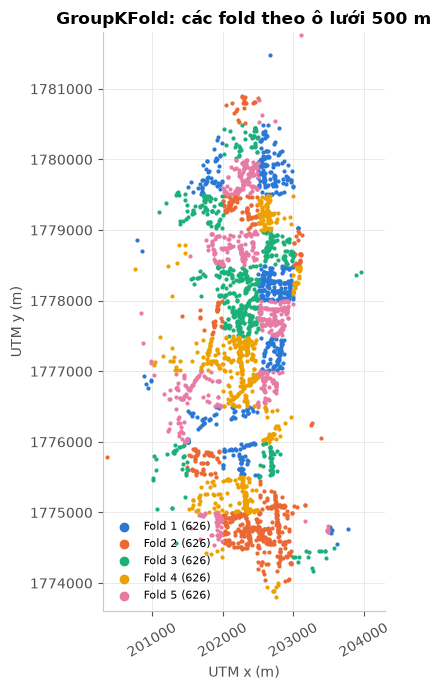

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
CVS = {"StratifiedKFold": (skf, None), "GroupKFold (ô 500 m)": (gkf, cells)}

fold_id = np.zeros(len(y), dtype=int)
for k, (_, te) in enumerate(gkf.split(X, y, cells)):
    fold_id[te] = k
xy = geo.to_utm(df[mask])
fig, ax = plt.subplots(figsize=(5.5, 7))
for k in range(5):
    s = fold_id == k
    ax.scatter(xy[s, 0], xy[s, 1], s=4, color=viz.PALETTE[k], label=f"Fold {k + 1} ({s.sum()})")
ax.set_aspect("equal"); ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", rotation=30)
ax.set_xlim(200300, 204300); ax.set_ylim(1773600, 1781800)
ax.set_title("GroupKFold: các fold theo ô lưới 500 m"); ax.set_xlabel("UTM x (m)"); ax.set_ylabel("UTM y (m)")
ax.legend(loc="lower left", fontsize=8, markerscale=3)
fig.tight_layout(); viz.save_fig(fig, "05_groupkfold_folds"); plt.show()

## 3. Chọn siêu tham số (theo GroupKFold)

Mỗi mô hình được thử một lưới nhỏ siêu tham số và chọn theo **F1-macro dưới GroupKFold**. Lý do chọn F1-macro: lớp mất cân bằng (3,8%–22%), và với bài toán gợi ý thì các lớp nhỏ như Tráng miệng hay Trà sữa quan trọng ngang lớp lớn.

In [5]:
grids = {
    "Decision Tree": [DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, class_weight="balanced",
                                             random_state=RANDOM_STATE) for d in (3, 5, 8, 12)],
    "KNN": [make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights="distance")) for k in (5, 15, 31, 61)],
    "Random Forest": [RandomForestClassifier(n_estimators=300, min_samples_leaf=l, max_features="sqrt",
                                             class_weight="balanced_subsample", n_jobs=4, random_state=RANDOM_STATE)
                      for l in (1, 5, 10, 20)],
    "Gradient Boosting": [HistGradientBoostingClassifier(max_depth=d, learning_rate=0.05, max_iter=200, class_weight="balanced",
                                                         random_state=RANDOM_STATE) for d in (3, 6)],
}
labels = {"Decision Tree": "max_depth", "KNN": "n_neighbors", "Random Forest": "min_samples_leaf", "Gradient Boosting": "max_depth"}
vals = {"Decision Tree": (3, 5, 8, 12), "KNN": (5, 15, 31, 61), "Random Forest": (1, 5, 10, 20), "Gradient Boosting": (3, 6)}
tune_rows, BEST = [], {}
for name, cands in grids.items():
    best = (-1, None)
    for v, mdl in zip(vals[name], cands):
        P, _ = md.oof_predict_proba(mdl, X, y, gkf, cells, CLASSES)
        r = md.metrics_from_proba(y, P, CLASSES)
        tune_rows.append(dict(model=name, param=f"{labels[name]}={v}", f1_macro=r["f1_macro"],
                              balanced_accuracy=r["balanced_accuracy"], roc_auc=r["roc_auc_ovr_macro"]))
        if r["f1_macro"] > best[0]:
            best = (r["f1_macro"], mdl)
    BEST[name] = best[1]
tune = pd.DataFrame(tune_rows)
tune.to_csv(TABLES / "05_hyperparameter_tuning.csv", index=False)
tune.round(3)

,model,param,f1_macro,balanced_accuracy,roc_auc
0,Decision Tree,max_depth=3,0.110,0.141,0.525
1,Decision Tree,max_depth=5,0.108,0.128,0.517
2,Decision Tree,max_depth=8,0.118,0.143,0.522
3,Decision Tree,max_depth=12,0.121,0.145,0.523
4,KNN,n_neighbors=5,0.131,0.131,0.519
5,KNN,n_neighbors=15,0.121,0.128,0.523
6,KNN,n_neighbors=31,0.119,0.133,0.536
7,KNN,n_neighbors=61,0.097,0.122,0.540
8,Random Forest,min_samples_leaf=1,0.122,0.136,0.532
9,Random Forest,min_samples_leaf=5,0.142,0.144,0.541


## 4. So sánh mô hình: CV ngẫu nhiên và CV không gian

Xử lý mất cân bằng theo hai cách:
- `class_weight="balanced"` cho Decision Tree, Logistic Regression, Random Forest và Gradient Boosting;
- **SMOTE đặt bên trong pipeline** (chỉ sinh mẫu trên fold train, không rò sang fold test) cho KNN và Naive Bayes, là hai mô hình không hỗ trợ class_weight.

In [6]:
MODELS = {
    "Baseline (lớp phổ biến nhất)": DummyClassifier(strategy="most_frequent"),
    "Baseline (ngẫu nhiên theo tỉ lệ)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Naive Bayes + SMOTE": imb_pipeline(StandardScaler(), SMOTE(random_state=RANDOM_STATE), GaussianNB()),
    "KNN + SMOTE": imb_pipeline(StandardScaler(), SMOTE(random_state=RANDOM_STATE), BEST["KNN"].steps[-1][1]),
    "Decision Tree": BEST["Decision Tree"],
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Random Forest": BEST["Random Forest"],
    "Gradient Boosting": BEST["Gradient Boosting"],
}
res, OOF = md.compare_models(MODELS, X, y, CVS, CLASSES)
res.to_csv(TABLES / "05_model_comparison.csv", index=False, encoding="utf-8-sig")
res.round(3)

,model,cv,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,top3_accuracy,roc_auc_ovr_macro,time_s
0,Baseline (lớp phổ biến nhất),StratifiedKFold,0.219,0.111,0.024,0.111,0.040,0.415,0.500,0.149
1,Baseline (ngẫu nhiên theo tỉ lệ),StratifiedKFold,0.141,0.113,0.113,0.113,0.113,0.324,0.501,0.146
2,Naive Bayes + SMOTE,StratifiedKFold,0.108,0.151,0.150,0.151,0.108,0.385,0.539,0.609
3,KNN + SMOTE,StratifiedKFold,0.258,0.252,0.242,0.252,0.239,0.504,0.596,0.685
4,Decision Tree,StratifiedKFold,0.149,0.179,0.163,0.179,0.150,0.421,0.556,0.569
5,Logistic Regression,StratifiedKFold,0.144,0.164,0.155,0.164,0.139,0.421,0.563,1.157
6,Random Forest,StratifiedKFold,0.258,0.240,0.231,0.240,0.234,0.543,0.623,18.307
7,Gradient Boosting,StratifiedKFold,0.335,0.292,0.313,0.292,0.300,0.623,0.685,85.062
8,Baseline (lớp phổ biến nhất),GroupKFold (ô 500 m),0.219,0.111,0.024,0.111,0.040,0.415,0.500,0.200
9,Baseline (ngẫu nhiên theo tỉ lệ),GroupKFold (ô 500 m),0.138,0.107,0.106,0.107,0.107,0.320,0.498,0.184


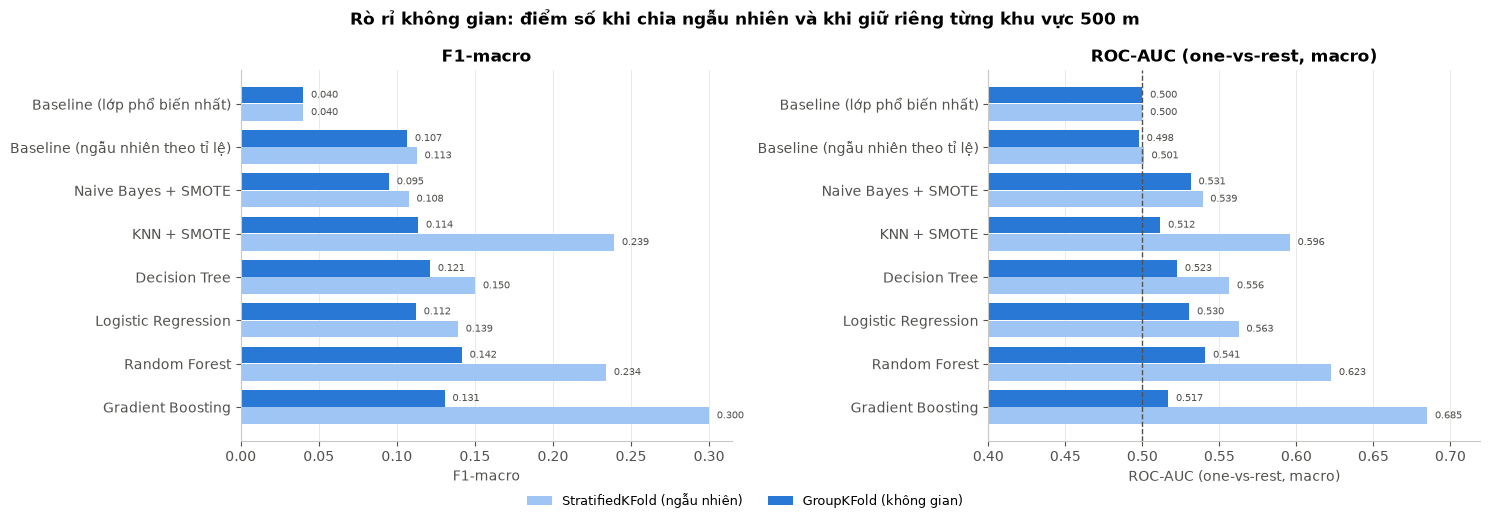

cv,GroupKFold (ô 500 m),StratifiedKFold,chenh_lech
model,,,
Gradient Boosting,0.131,0.300,0.169
KNN + SMOTE,0.114,0.239,0.126
Random Forest,0.142,0.234,0.092
Decision Tree,0.121,0.150,0.029
Logistic Regression,0.112,0.139,0.027
Naive Bayes + SMOTE,0.095,0.108,0.013
Baseline (ngẫu nhiên theo tỉ lệ),0.107,0.113,0.006
Baseline (lớp phổ biến nhất),0.040,0.040,0.000


In [7]:
piv = res.pivot(index="model", columns="cv", values="f1_macro").reindex(list(MODELS))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in [(axes[0], "f1_macro", "F1-macro"), (axes[1], "roc_auc_ovr_macro", "ROC-AUC (one-vs-rest, macro)")]:
    p = res.pivot(index="model", columns="cv", values=metric).reindex(list(MODELS))[["StratifiedKFold", "GroupKFold (ô 500 m)"]]
    yy = np.arange(len(p))
    ax.barh(yy + 0.2, p["StratifiedKFold"], height=0.38, color="#9ec5f4", label="StratifiedKFold (ngẫu nhiên)")
    ax.barh(yy - 0.2, p["GroupKFold (ô 500 m)"], height=0.38, color=viz.PALETTE[0], label="GroupKFold (không gian)")
    for i, (a, b) in enumerate(zip(p["StratifiedKFold"], p["GroupKFold (ô 500 m)"])):
        ax.text(a + 0.005, i + 0.2, f"{a:.3f}", va="center", fontsize=7.5, color=viz.TEXT_2)
        ax.text(b + 0.005, i - 0.2, f"{b:.3f}", va="center", fontsize=7.5, color=viz.TEXT_2)
    ax.set_yticks(yy, p.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_title(title); ax.set_xlabel(title)
    if metric == "roc_auc_ovr_macro":
        ax.axvline(0.5, color=viz.TEXT_2, ls="--", lw=1); ax.set_xlim(0.4, None)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Rò rỉ không gian: điểm số khi chia ngẫu nhiên và khi giữ riêng từng khu vực 500 m", fontweight="bold")
fig.tight_layout(); viz.save_fig(fig, "05_cv_comparison"); plt.show()

gap = (res.pivot(index="model", columns="cv", values="f1_macro").assign(
    chenh_lech=lambda d: d["StratifiedKFold"] - d["GroupKFold (ô 500 m)"])).round(3)
gap.sort_values("chenh_lech", ascending=False)

## 5. Mô hình tốt nhất (theo GroupKFold)

In [8]:
g = res[(res["cv"] == "GroupKFold (ô 500 m)") & ~res["model"].str.startswith("Baseline")]
BEST_NAME = g.sort_values("f1_macro", ascending=False).iloc[0]["model"]
P_best = OOF[(BEST_NAME, "GroupKFold (ô 500 m)")]
pred = CLASSES[P_best.argmax(axis=1)]
base = res[(res["cv"] == "GroupKFold (ô 500 m)") & (res["model"] == "Baseline (lớp phổ biến nhất)")].iloc[0]
best = g.set_index("model").loc[BEST_NAME]
print(f"Mô hình tốt nhất: {BEST_NAME}")
for m_ in ["accuracy", "balanced_accuracy", "f1_macro", "top3_accuracy", "roc_auc_ovr_macro"]:
    print(f"  {m_:<20} {best[m_]:.3f}   (baseline lớp phổ biến nhất: {base[m_]:.3f})")
print()
print(classification_report(y, pred, labels=CLASSES, zero_division=0, digits=3))

Mô hình tốt nhất: Random Forest
  accuracy             0.175   (baseline lớp phổ biến nhất: 0.219)
  balanced_accuracy    0.144   (baseline lớp phổ biến nhất: 0.111)
  f1_macro             0.142   (baseline lớp phổ biến nhất: 0.040)
  top3_accuracy        0.460   (baseline lớp phổ biến nhất: 0.415)
  roc_auc_ovr_macro    0.541   (baseline lớp phổ biến nhất: 0.500)

                     precision    recall  f1-score   support

       Bún/Phở/Cháo      0.189     0.156     0.171       588
      Cà phê & nước      0.305     0.328     0.316       687
                Cơm      0.097     0.094     0.096       340
 Cửa hàng thực phẩm      0.138     0.194     0.161       232
Fast food & Quốc tế      0.121     0.118     0.119       221
        Lẩu & Nướng      0.092     0.111     0.100       234
            Trà sữa      0.089     0.074     0.081       216
        Tráng miệng      0.053     0.067     0.059       120
   Ăn vặt & Bánh mì      0.186     0.159     0.171       492

           accuracy 

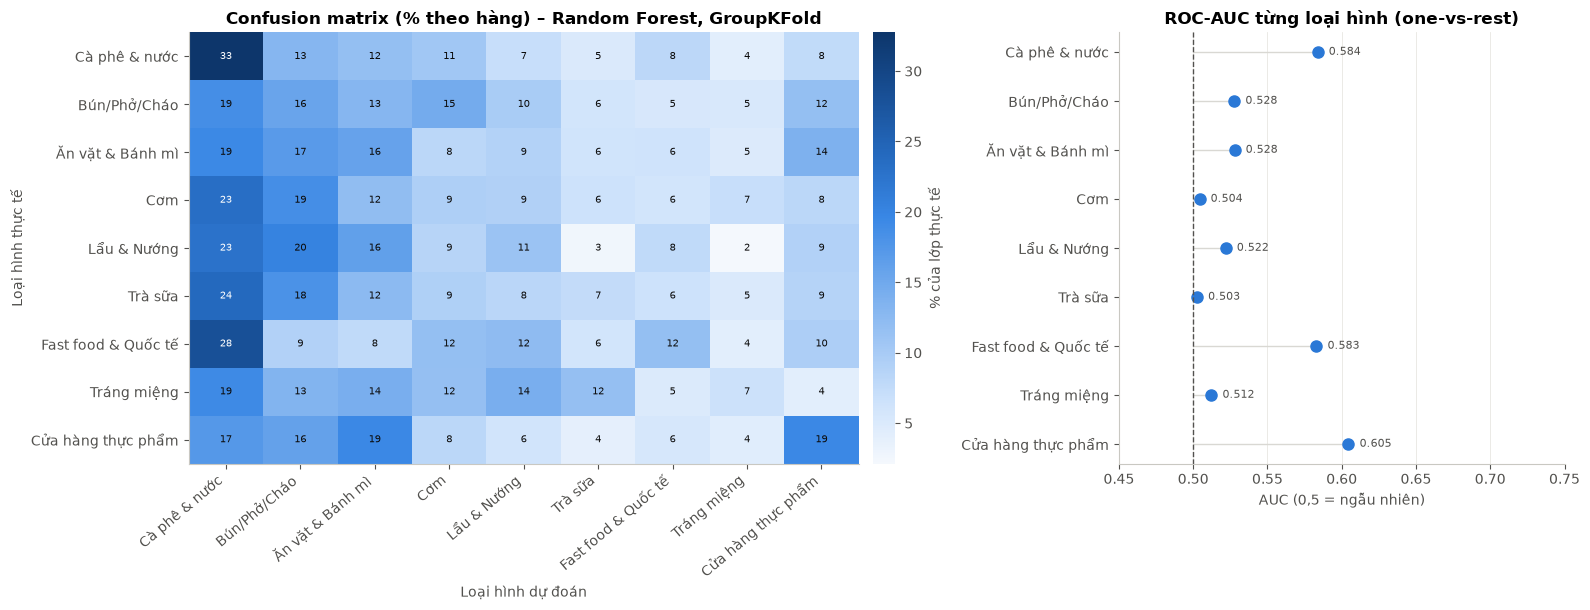

In [9]:
cm = confusion_matrix(y, pred, labels=CLASSES, normalize="true") * 100
order = [c for c in ft.GROUP_ORDER if c in CLASSES]
idx = [list(CLASSES).index(c) for c in order]
cm_df = pd.DataFrame(cm[np.ix_(idx, idx)], index=order, columns=order)
auc_c = md.per_class_auc(y, P_best, CLASSES).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={"width_ratios": [1.6, 1]})
viz.heatmap(cm_df, f"Confusion matrix (% theo hàng) – {BEST_NAME}, GroupKFold",
            "Loại hình dự đoán", "Loại hình thực tế", fmt=".0f", ax=axes[0], cbar_label="% của lớp thực tế")
s = auc_c.iloc[::-1]
axes[1].hlines(s.index, 0.5, s.values, color="#d9d8d3", lw=1)
axes[1].plot(s.values, s.index, "o", ms=8, color=viz.PALETTE[0])
for i, v in s.items():
    axes[1].annotate(f"{v:.3f}", (v, i), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=viz.TEXT_2)
axes[1].axvline(0.5, color=viz.TEXT_2, ls="--", lw=1)
axes[1].set_xlim(0.45, 0.75); axes[1].set_title("ROC-AUC từng loại hình (one-vs-rest)")
axes[1].set_xlabel("AUC (0,5 = ngẫu nhiên)"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); viz.save_fig(fig, "05_confusion_auc"); plt.show()

## 6. Yếu tố nào quyết định loại hình? Feature importance và permutation importance

- **Impurity importance** (Random Forest, huấn luyện trên toàn bộ dữ liệu) dễ tính nhưng thiên vị đặc trưng liên tục, có nhiều giá trị.
- **Permutation importance** được tính trên **fold test của GroupKFold**: xáo trộn một **nhóm** đặc trưng rồi đo ROC-AUC giảm bao nhiêu. Cách này tin cậy hơn và chỉ đo phần tín hiệu tổng quát hóa được sang khu vực mới.
  Ta hoán vị theo nhóm vì các đặc trưng trong cùng nhóm tương quan cao, hoán vị riêng lẻ sẽ đánh giá thấp vai trò của chúng.

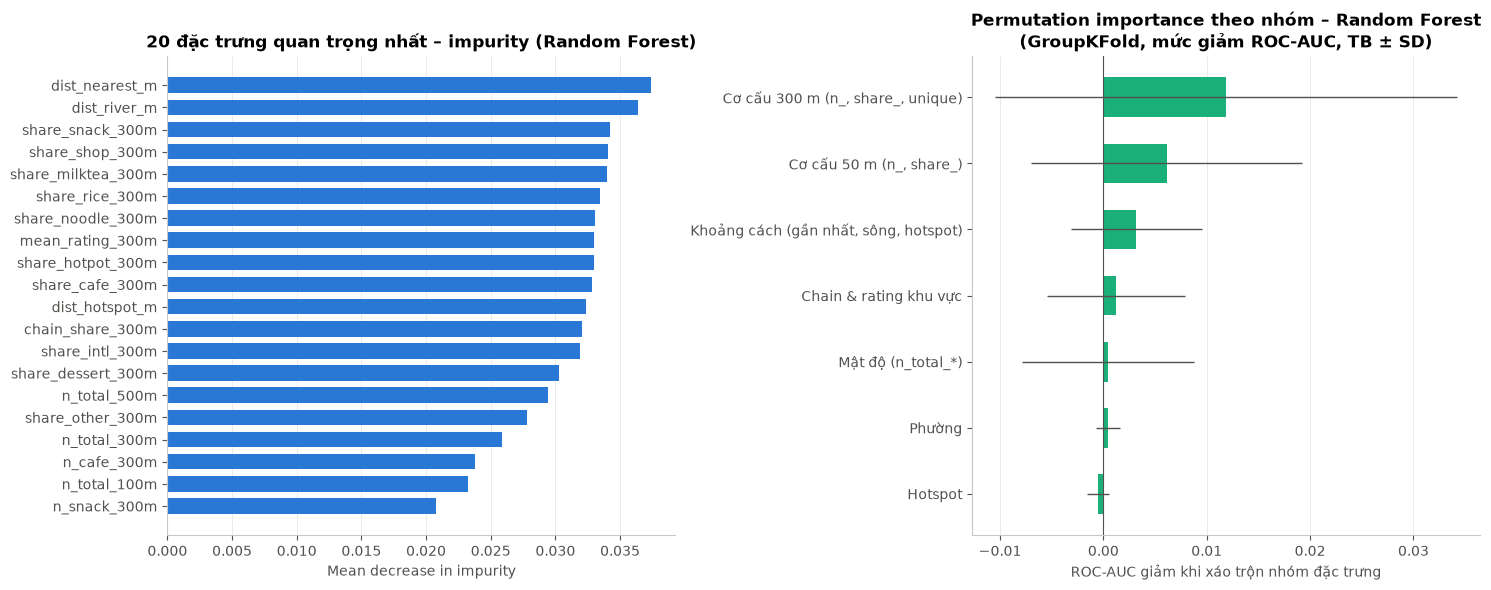

,mean,std
family,,
"Cơ cấu 300 m (n_, share_, unique)",0.0119,0.0223
"Cơ cấu 50 m (n_, share_)",0.0061,0.0131
"Khoảng cách (gần nhất, sông, hotspot)",0.0032,0.0063
Chain & rating khu vực,0.0012,0.0067
Mật độ (n_total_*),0.0005,0.0083
Phường,0.0004,0.0012
Hotspot,-0.0005,0.0011


In [10]:
from sklearn.base import clone
rf_full = clone(BEST["Random Forest"]).fit(X, y)
imp = pd.Series(rf_full.feature_importances_, index=FEATURES).sort_values(ascending=False)

families = {
    "Cơ cấu 50 m (n_, share_)": [c for c in FEATURES if c.endswith("_50m") and c != "n_total_50m"],
    "Cơ cấu 300 m (n_, share_, unique)": [c for c in FEATURES if c.endswith("_300m") and c not in
                                         ("n_total_300m", "chain_share_300m", "mean_rating_300m")],
    "Mật độ (n_total_*)": [c for c in FEATURES if c.startswith("n_total_")],
    "Chain & rating khu vực": ["chain_share_300m", "mean_rating_300m"],
    "Khoảng cách (gần nhất, sông, hotspot)": ["dist_nearest_m", "dist_river_m", "dist_hotspot_m"],
    "Hotspot": ["is_hotspot"],
    "Phường": [c for c in FEATURES if c.startswith("ward_")],
}
rng = np.random.default_rng(RANDOM_STATE)
perm_rows = []
model_for_perm = MODELS[BEST_NAME] if BEST_NAME in MODELS else BEST["Random Forest"]
for k, (tr, te) in enumerate(gkf.split(X, y, cells)):
    mdl = clone(model_for_perm).fit(X.iloc[tr], y[tr])
    Xte = X.iloc[te]
    base_auc = roc_auc_score(y[te], mdl.predict_proba(Xte), multi_class="ovr", labels=mdl.classes_)
    for fam, cols in families.items():
        for rep in range(5):
            Xp = Xte.copy()
            perm = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].to_numpy()[perm]
            auc = roc_auc_score(y[te], mdl.predict_proba(Xp), multi_class="ovr", labels=mdl.classes_)
            perm_rows.append(dict(fold=k, family=fam, drop_auc=base_auc - auc))
perm = pd.DataFrame(perm_rows).groupby("family")["drop_auc"].agg(["mean", "std"]).sort_values("mean", ascending=False)
perm.to_csv(TABLES / "05_permutation_importance_groups.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
s = imp.head(20).iloc[::-1]
axes[0].barh(s.index, s.values, color=viz.PALETTE[0], height=0.7)
axes[0].set_title("20 đặc trưng quan trọng nhất – impurity (Random Forest)")
axes[0].set_xlabel("Mean decrease in impurity"); axes[0].grid(axis="y", visible=False)
p = perm.iloc[::-1]
axes[1].barh(p.index, p["mean"], xerr=p["std"], color=viz.PALETTE[2], height=0.6, error_kw=dict(ecolor=viz.TEXT_2, lw=1))
axes[1].axvline(0, color=viz.TEXT_2, lw=0.8)
axes[1].set_title(f"Permutation importance theo nhóm – {BEST_NAME}\n(GroupKFold, mức giảm ROC-AUC, TB ± SD)")
axes[1].set_xlabel("ROC-AUC giảm khi xáo trộn nhóm đặc trưng"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); viz.save_fig(fig, "05_feature_importance"); plt.show()
perm.round(4)

## 7. Lưu mô hình và dự đoán

- **Mô hình cuối:** mô hình tốt nhất được huấn luyện lại trên toàn bộ dữ liệu có nhãn, sau đó lưu ra `outputs/models/type_model.joblib`. Mô hình này dùng cho công cụ gợi ý ở notebook 06.
- **Dự đoán cho từng cửa hàng:** dùng **xác suất out-of-fold của GroupKFold**, tức mỗi cửa hàng được chấm bởi mô hình *không* thấy khu vực của nó. Nhờ vậy cột `pred_*` trung thực, không bị rò rỉ.
- **Chỉ số phù hợp (suitability)** của loại hình *c* tại vị trí *x* được tính bằng P(c | x) / P̄(c), trong đó P̄(c) là **xác suất trung bình mà mô hình gán cho lớp c** trên mọi cửa hàng (out-of-fold).
  Ta không chia cho tỉ lệ nền thật, vì mô hình huấn luyện với `class_weight="balanced"` nên xác suất bị kéo về gần đều giữa các lớp. Nếu chia cho tỉ lệ nền thật, các lớp hiếm như Tráng miệng sẽ bị thổi phồng một cách hệ thống.
  Giá trị **> 1** nghĩa là *theo mô hình*, vị trí này hợp với loại hình c hơn một vị trí trung bình trong quận.

In [11]:
final_model = clone(MODELS[BEST_NAME]).fit(X, y)
(ROOT / "outputs" / "models").mkdir(parents=True, exist_ok=True)
prior = P_best.mean(axis=0)   # xác suất TB mô hình gán cho từng lớp (OOF) – mốc so sánh của chỉ số phù hợp
print("Xác suất TB theo lớp (mốc):", dict(zip(CLASSES, prior.round(3))))
joblib.dump({"model": final_model, "features": FEATURES, "classes": CLASSES, "prior": prior, "name": BEST_NAME,
             "ward_columns": list(ward_oh.columns)}, ROOT / "outputs" / "models" / "type_model.joblib")

# xác suất OOF (GroupKFold) cho cửa hàng có nhãn; cửa hàng nhóm 'Khác' -> dùng mô hình cuối
P_all = np.zeros((len(df), len(CLASSES)))
P_all[mask] = P_best
P_all[~mask] = final_model.predict_proba(X_all[~mask])
pred_df = pd.DataFrame(P_all, columns=[f"proba_{ft.GROUP_SLUG[c]}" for c in CLASSES])
pred_df.insert(0, "storeId", df["storeId"].values)
pred_df["pred_type"] = CLASSES[P_all.argmax(axis=1)]
top3 = np.argsort(-P_all, axis=1)[:, :3]
pred_df["pred_top3"] = [" | ".join(CLASSES[i]) for i in top3]
suit = P_all / prior
pred_df["best_fit_type"] = CLASSES[suit.argmax(axis=1)]
pred_df["best_fit_lift"] = suit.max(axis=1)
own_idx = pd.Series(df["type_group"]).map({c: i for i, c in enumerate(CLASSES)})
pred_df["own_type_suitability"] = [suit[i, int(j)] if pd.notna(j) else np.nan for i, j in enumerate(own_idx)]
pred_df["pred_source"] = np.where(mask, "OOF GroupKFold", "final model (nhóm Khác)")
pred_df.to_csv(PROC / "stores_predictions.csv", index=False, encoding="utf-8-sig")
print("Đã ghi:", (PROC / "stores_predictions.csv").relative_to(ROOT), pred_df.shape)
print(f"Tỉ lệ cửa hàng mà loại hình hiện tại được môi trường 'ủng hộ' (suitability > 1): "
      f"{(pred_df.loc[mask, 'own_type_suitability'] > 1).mean():.1%}")
pred_df.head()

Xác suất TB theo lớp (mốc): {np.str_('Bún/Phở/Cháo'): np.float64(0.129), np.str_('Cà phê & nước'): np.float64(0.137), np.str_('Cơm'): np.float64(0.118), np.str_('Cửa hàng thực phẩm'): np.float64(0.105), np.str_('Fast food & Quốc tế'): np.float64(0.096), np.str_('Lẩu & Nướng'): np.float64(0.106), np.str_('Trà sữa'): np.float64(0.096), np.str_('Tráng miệng'): np.float64(0.085), np.str_('Ăn vặt & Bánh mì'): np.float64(0.128)}


Đã ghi: data\processed\stores_predictions.csv (3208, 16)
Tỉ lệ cửa hàng mà loại hình hiện tại được môi trường 'ủng hộ' (suitability > 1): 49.8%


,storeId,proba_noodle,proba_cafe,proba_rice,proba_shop,proba_intl,proba_hotpot,proba_milktea,proba_dessert,proba_snack,pred_type,pred_top3,best_fit_type,best_fit_lift,own_type_suitability,pred_source
0,FOOD07176572,0.134762,0.132157,0.110636,0.116688,0.091940,0.074332,0.115715,0.100639,0.123133,Bún/Phở/Cháo,Bún/Phở/Cháo | Cà phê & nước | Ăn vặt & Bánh mì,Trà sữa,1.207902,1.047664,OOF GroupKFold
1,FOOD10740777,0.161904,0.097028,0.089745,0.126433,0.072852,0.182527,0.064535,0.081296,0.123680,Lẩu & Nướng,Lẩu & Nướng | Bún/Phở/Cháo | Cửa hàng thực phẩm,Lẩu & Nướng,1.715831,0.762815,OOF GroupKFold
2,FOOD99622263,0.177518,0.145476,0.133065,0.100161,0.091557,0.118860,0.062096,0.055852,0.115416,Bún/Phở/Cháo,Bún/Phở/Cháo | Cà phê & nước | Cơm,Bún/Phở/Cháo,1.380057,0.900183,OOF GroupKFold
3,FOOD60493949,0.075855,0.229373,0.094266,0.094419,0.070108,0.173391,0.066776,0.113128,0.082684,Cà phê & nước,Cà phê & nước | Lẩu & Nướng | Tráng miệng,Cà phê & nước,1.674941,1.674941,OOF GroupKFold
4,FOOD49035371,0.097273,0.138617,0.055102,0.214758,0.226238,0.052518,0.067488,0.039525,0.108481,Fast food & Quốc tế,Fast food & Quốc tế | Cửa hàng thực phẩm | Cà phê & nước,Fast food & Quốc tế,2.366342,0.462746,OOF GroupKFold


## 8. Kết luận

1. **Đánh giá ngẫu nhiên đánh giá quá cao năng lực mô hình.** Với StratifiedKFold, Gradient Boosting đạt F1-macro 0,300 và AUC 0,685. Khi giữ riêng từng khu vực 500 m (GroupKFold), con số này chỉ còn 0,131 và 0,517.
   Mức chênh lệch lớn nhất thuộc về các mô hình linh hoạt (Gradient Boosting −0,17, KNN −0,13, Random Forest −0,09). Lý do là các mô hình này "nhớ" được quan hệ giữa những quán sát vách nhau.
   **Bài học phương pháp:** với dữ liệu không gian, *bắt buộc* phải đánh giá bằng CV theo nhóm không gian.
2. **Dưới đánh giá không gian, mô hình tốt nhất là Random Forest** (min_samples_leaf = 5, class_weight cân bằng). Kết quả: F1-macro 0,142 (baseline lớp phổ biến nhất: 0,040; baseline ngẫu nhiên theo tỉ lệ: 0,107), balanced accuracy 0,144 (baseline 0,111), ROC-AUC 0,541, top-3 accuracy 0,460 (baseline 0,415).
   Mô hình **tốt hơn ngẫu nhiên nhưng yếu**.
3. **Loại hình dễ đoán nhất là Cà phê & nước** (F1 0,32), sau đó là Bún/Phở/Cháo, Ăn vặt & Bánh mì và Cửa hàng thực phẩm (F1 khoảng 0,16–0,17).
   Theo AUC, nhóm phân biệt tốt nhất là **Cửa hàng thực phẩm (0,61)**, Cà phê và Fast food (khoảng 0,58). Tráng miệng, Trà sữa và Cơm gần như không đoán được (AUC ≈ 0,50–0,51, F1 < 0,1).
   Điều này khớp với notebook 04: Cửa hàng thực phẩm (quanh chợ) và Fast food (trong TTTM, khu ẩm thực) là các nhóm tụ cụm rõ nhất.
4. **Yếu tố quan trọng nhất là cơ cấu loại hình trong bán kính 300 m**, tiếp theo là cơ cấu 50 m và các khoảng cách (permutation importance theo nhóm). Mật độ thuần túy, phường và cờ hotspot gần như không đóng góp thêm khi đã biết cơ cấu xung quanh.
   Nói cách khác, *"xung quanh đang bán gì"* nói nhiều hơn *"xung quanh đông hay vắng"*.
   Lưu ý: độ lệch chuẩn giữa các fold rất lớn (thanh sai số cắt qua 0), nên thứ hạng này chỉ mang tính **gợi ý**, chưa chắc chắn về mặt thống kê.
5. **Diễn giải kinh doanh:**
   - Ở Hải Châu, gần như loại hình nào cũng có thể xuất hiện ở gần như mọi khu vực, vì thị trường trộn lẫn. Kết quả này nhất quán với notebook 04 (lift đồng vị trí chỉ 0,84–1,26 ở 100 m).
   - Môi trường xung quanh chỉ **gợi ý nhẹ**. Vì vậy ở notebook 06, mô hình chỉ là *một trong bốn* thành phần của điểm vị trí, với trọng số 0,20, bên cạnh mật độ, mức cạnh tranh và luật đồng vị trí.
   - Muốn dự đoán tốt hơn cần dữ liệu về **nhu cầu**: dân số, văn phòng, trường học, lưu lượng người qua lại, giá thuê. Đây là hướng của vòng Feedback tiếp theo.